# Bayesian networks for heart disease prediction


This notebook compares an expert-designed Bayesian network with a network learned from data using **Python bnlearn**.

**The question is whether the recorded clinical measurements can distinguish patients with and without heart disease.**


**Guide:** preparation → exploratory analysis → two DAGs → CPTs → inference → test evaluation → reflection.


## 1. Method and reproducibility
A **directed acyclic graph (DAG)** contains arrows but no directed cycles. Each node has a **conditional probability table (CPT)**: probabilities for that variable given its parents. Together they define a joint probability distribution, `P(all variables) = product of P(node | parents)`.

We reserve 20% of patients for testing, using stratification to preserve class balance. Imputation, bin boundaries, structure learning and CPT fitting use training data only. The test labels are used only for the final comparison. Both networks use the same rows, states and BDeu smoothing (equivalent sample size, ESS = 5). The classification threshold is fixed at 0.50 before evaluation.

### Key assumptions
Patient records are treated as independent. Missing categories are filled with training modes. Discretisation trades numerical detail for smaller CPTs. The expert arrows are modelling assumptions; observational data do not prove causal effects. The sample is small and clinically selected, so results do not establish performance in the general population.



In [ ]:
# In a fresh Colab runtime, uncomment and run once:
# %pip install -q bnlearn==0.12.0 pgmpy==0.1.25
from pathlib import Path
from itertools import product
from importlib.metadata import version
import hashlib, json, pickle, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import bnlearn as bn
from pgmpy.models import BayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, mutual_info_score)
from IPython.display import display, Markdown, HTML
SEED, ESS, THRESHOLD = 42, 5, 0.50
TARGET = 'heartdisease_bin'
OUT = Path('results'); OUT.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
VERSIONS = {p: version(p) for p in ['bnlearn','pgmpy','numpy','pandas','scikit-learn','networkx','matplotlib']}
print('Python', platform.python_version()); display(pd.Series(VERSIONS, name='Version'))

Python 3.12.0


bnlearn         0.12.0
pgmpy           0.1.25
numpy            2.2.6
pandas           2.3.2
scikit-learn     1.7.1
networkx           3.7
matplotlib      3.10.6
Name: Version, dtype: object

## 2. Import and check the supplied data
The code looks in common local and Colab locations. `?` means missing, not zero. We verify the schema, category codes, numeric conversion and duplicates before modelling. The CSV column `gender` is renamed `sex` to match the assignment's coding; this is a label change only.

In [ ]:
candidates = [Path('Data/diabetes.csv'), Path('../Data/diabetes.csv'), Path('diabetes.csv'), Path('/content/diabetes.csv')]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Upload diabetes.csv to Colab or place it in Data/ beside this notebook.')
raw = pd.read_csv(DATA_PATH, dtype='string', keep_default_na=False)
raw.columns = raw.columns.str.strip().str.lower()
raw = raw.apply(lambda c: c.str.strip()).rename(columns={'gender':'sex'})
expected = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','heartdisease']
assert set(raw.columns) == set(expected), 'Unexpected schema'
df = raw.replace(['?', '', 'NA', 'N/A', 'null'], pd.NA).apply(pd.to_numeric, errors='raise').astype(float)
allowed = {'sex':[0,1], 'cp':[1,2,3,4], 'fbs':[0,1], 'restecg':[0,1,2], 'exang':[0,1],
           'slope':[1,2,3], 'ca':[0,1,2,3], 'thal':[3,6,7], 'heartdisease':[0,1,2,3,4]}
for name, states in allowed.items():
    assert df[name].dropna().isin(states).all(), f'Invalid codes: {name}'
assert df.heartdisease.notna().all()
assert np.isfinite(df.dropna().to_numpy()).all()
assert df.age.between(18,120).all()
assert (df[['trestbps','chol','thalach']] > 0).all().all()
assert (df.oldpeak >= 0).all()
print(f'{len(df)} records, {len(df.columns)} columns; exact duplicate copies: {df.duplicated().sum()}')
audit = pd.DataFrame({'dtype':df.dtypes.astype(str), 'missing_n':df.isna().sum(),
                      'missing_%':100*df.isna().mean(), 'distinct':df.nunique()})
display(audit); display(df.head())
SOURCE_HASH = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print('Source SHA256:', SOURCE_HASH)

303 records, 14 columns; exact duplicate copies: 0


,dtype,missing_n,missing_%,distinct
age,float64,0,0.0000,41
sex,float64,0,0.0000,2
cp,float64,0,0.0000,4
trestbps,float64,0,0.0000,50
chol,float64,0,0.0000,152
fbs,float64,0,0.0000,2
restecg,float64,0,0.0000,3
thalach,float64,0,0.0000,91
exang,float64,0,0.0000,2
oldpeak,float64,0,0.0000,40


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heartdisease
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0.0


Source SHA256: ee2cfb0aed4254ceb04befb1cb669fd93e96ffb248d1466927e3901277e2da97


### Data dictionary
- `age`: years
- `trestbps`: resting blood pressure (mm Hg)
- `chol`: serum cholesterol (mg/dl)
- `thalach`: maximum achieved heart rate (beats/min)
- `oldpeak`: exercise ST depression relative to rest.
- `sex`: 0 female, 1 male
- `cp`: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic
- `fbs`: 1 means fasting blood sugar >120 mg/dl
- `restecg`: 0 normal, 1 ST–T abnormality, 2 probable/definite left ventricular hypertrophy
- `exang`: exercise-induced angina, 0 no / 1 yes
- `slope`: 1 upsloping, 2 flat, 3 downsloping
- `ca`: number of major vessels coloured by fluoroscopy (0–3)
- `thal`: 3 normal, 6 fixed defect, 7 reversible defect.

These codes follow the assignment and the [UCI Heart Disease documentation](https://archive.ics.uci.edu/dataset/45/heart+disease).

There are six missing cells: four in `ca` and two in `thal`. There are no exact duplicate rows. Missingness is small, but mode imputation can reduce variation and does not represent uncertainty about the missing values.

### Split before fitting preprocessing rules
We remove the original outcome from the predictors. Otherwise, the model could learn the answer directly: this is **target leakage**. No patients are dropped for missing predictors.

,n,no disease,disease,disease_%
split,,,,
All,303,164,139,45.8746
Train,242,131,111,45.8678
Test,61,33,28,45.9016


,fill,train_missing,test_missing
age,56.0,0,0
ca,0.0,1,3
chol,244.5,0,0
cp,4.0,0,0
exang,0.0,0,0
fbs,0.0,0,0
oldpeak,0.8,0,0
restecg,0.0,0,0
sex,1.0,0,0
slope,1.0,0,0


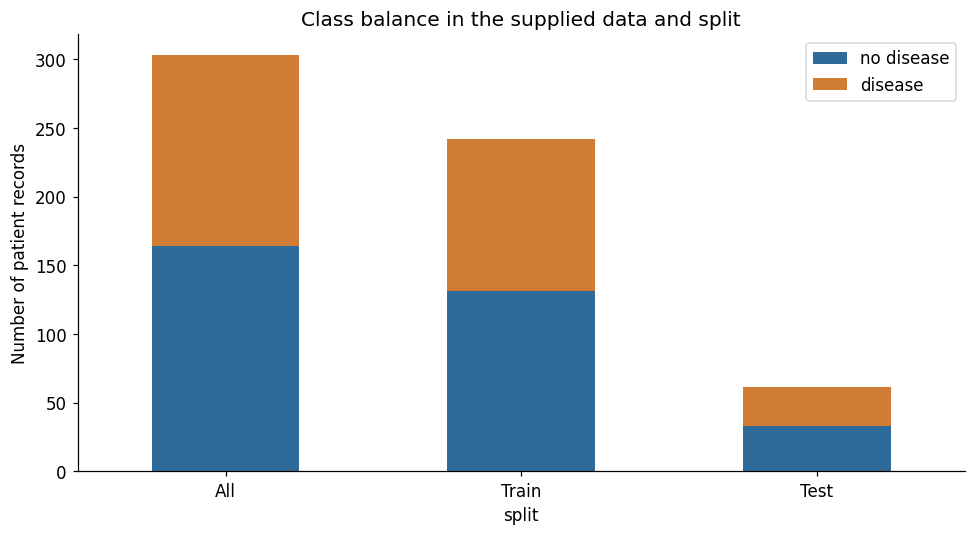

In [ ]:
continuous = ['age','trestbps','chol','thalach','oldpeak']
categorical = [x for x in allowed if x != 'heartdisease']
y = (df.heartdisease > 0).astype(int).rename(TARGET)
X = df.drop(columns='heartdisease')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
fill_values = {c: float(X_train[c].median()) for c in continuous}
fill_values.update({c: int(X_train[c].mode().iloc[0]) for c in categorical})
train_imputed, test_imputed = X_train.fillna(fill_values), X_test.fillna(fill_values)
balance = pd.DataFrame([{'split':name, 'n':len(s), 'no disease':int((s==0).sum()),
                         'disease':int(s.sum()), 'disease_%':100*s.mean()}
                        for name,s in [('All',y),('Train',y_train),('Test',y_test)]]).set_index('split')
display(balance)
display(pd.DataFrame({'fill':fill_values, 'train_missing':X_train.isna().sum(), 'test_missing':X_test.isna().sum()}))
ax = balance[['no disease','disease']].plot.bar(stacked=True, color=['#2F6B9A','#D17C35'], rot=0)
ax.set(ylabel='Number of patient records', title='Class balance in the supplied data and split')
plt.tight_layout(); plt.show()

The training set contains 242 patients and the test set contains 61. Disease prevalence is similar in both sets because the split is stratified. The moderate class imbalance does not justify synthetic oversampling here. We report disease recall and precision as well as accuracy, so errors in the positive class remain visible.

### Discretisation and final modelling data
A discrete Bayesian network needs a small set of states for each variable. For age, blood pressure, cholesterol and heart rate, training tertiles define `Low`, `Medium` and `High`. These are relative data bands, **not clinical diagnostic thresholds**. For oldpeak, zero is its own state; positive values are split at their training median. This respects the large group with no recorded ST depression.

The same frozen cut-offs are applied to the test set. Infinite outer boundaries keep valid new values inside a band. We retain all 13 predictors to compare structures on the same information. This increases CPT sparsity, so support counts and smoothing sensitivity are reported later.

In [ ]:
bin_specs = {}
for c in continuous:
    if c == 'oldpeak':
        cuts = [0., float(train_imputed.loc[train_imputed.oldpeak > 0, 'oldpeak'].median())]
        labels = ['No depression','Moderate','High']
    else:
        cuts = np.unique(train_imputed[c].quantile([1/3,2/3]).to_numpy()).tolist()
        labels = ['Low','Medium','High'] if len(cuts)==2 else ['Low','High']
    bin_specs[c] = {'edges':[-np.inf,*cuts,np.inf], 'labels':labels}

def transform_predictors(frame):
    result = frame.copy().fillna(fill_values)
    for c,spec in bin_specs.items():
        result[c+'_cat'] = pd.cut(result[c], bins=spec['edges'], labels=spec['labels'], include_lowest=True).astype(object)
    result = result.drop(columns=continuous)
    for c in categorical: result[c] = result[c].astype(int)
    assert not result.isna().any().any()
    return result

train = transform_predictors(X_train); test = transform_predictors(X_test)
train[TARGET], test[TARGET] = y_train, y_test
NODES = list(train.columns)
STATES = {c: sorted(train[c].unique().tolist(), key=str) for c in NODES}
for c in NODES: assert set(test[c]).issubset(STATES[c]), f'Unseen test state: {c}'
display(pd.DataFrame([{'variable':c, 'cut-offs':s['edges'][1:-1], 'states':s['labels']} for c,s in bin_specs.items()]))
display(pd.DataFrame({'node':NODES, 'states':[STATES[c] for c in NODES]}))
print('Final training/test shapes:', train.shape, test.shape)
display(train.head())
train.to_csv(OUT/'training_discrete.csv', index_label='source_row')
test.to_csv(OUT/'test_discrete.csv', index_label='source_row')

,variable,cut-offs,states
0,age,"[51.0, 59.0]","[Low, Medium, High]"
1,trestbps,"[120.0, 139.33333333333326]","[Low, Medium, High]"
2,chol,"[226.0, 266.66666666666663]","[Low, Medium, High]"
3,thalach,"[143.0, 162.0]","[Low, Medium, High]"
4,oldpeak,"[0.0, 1.2]","[No depression, Moderate, High]"


,node,states
0,sex,"[0, 1]"
1,cp,"[1, 2, 3, 4]"
2,fbs,"[0, 1]"
3,restecg,"[0, 1, 2]"
4,exang,"[0, 1]"
5,slope,"[1, 2, 3]"
6,ca,"[0, 1, 2, 3]"
7,thal,"[3, 6, 7]"
8,age_cat,"[High, Low, Medium]"
9,trestbps_cat,"[High, Low, Medium]"


Final training/test shapes: (242, 14) (61, 14)


,sex,cp,fbs,restecg,exang,slope,ca,thal,age_cat,trestbps_cat,chol_cat,thalach_cat,oldpeak_cat,heartdisease_bin
180,1,4,0,2,0,2,0,7,Low,Medium,High,High,Moderate,1
208,1,2,0,0,0,1,0,3,Medium,Medium,Medium,Medium,No depression,0
167,0,2,1,2,1,1,1,3,Medium,Medium,High,Medium,No depression,0
105,1,2,0,0,0,1,0,7,Medium,Low,High,Medium,No depression,0
297,0,4,0,0,1,2,0,7,Medium,High,Medium,Low,Moderate,1


## 3. Exploratory analysis
The following plots use training data only. Histograms show the spread of numerical variables and the cut-offs. Category disease rates are unadjusted associations: they do not hold other variables constant or establish causes.

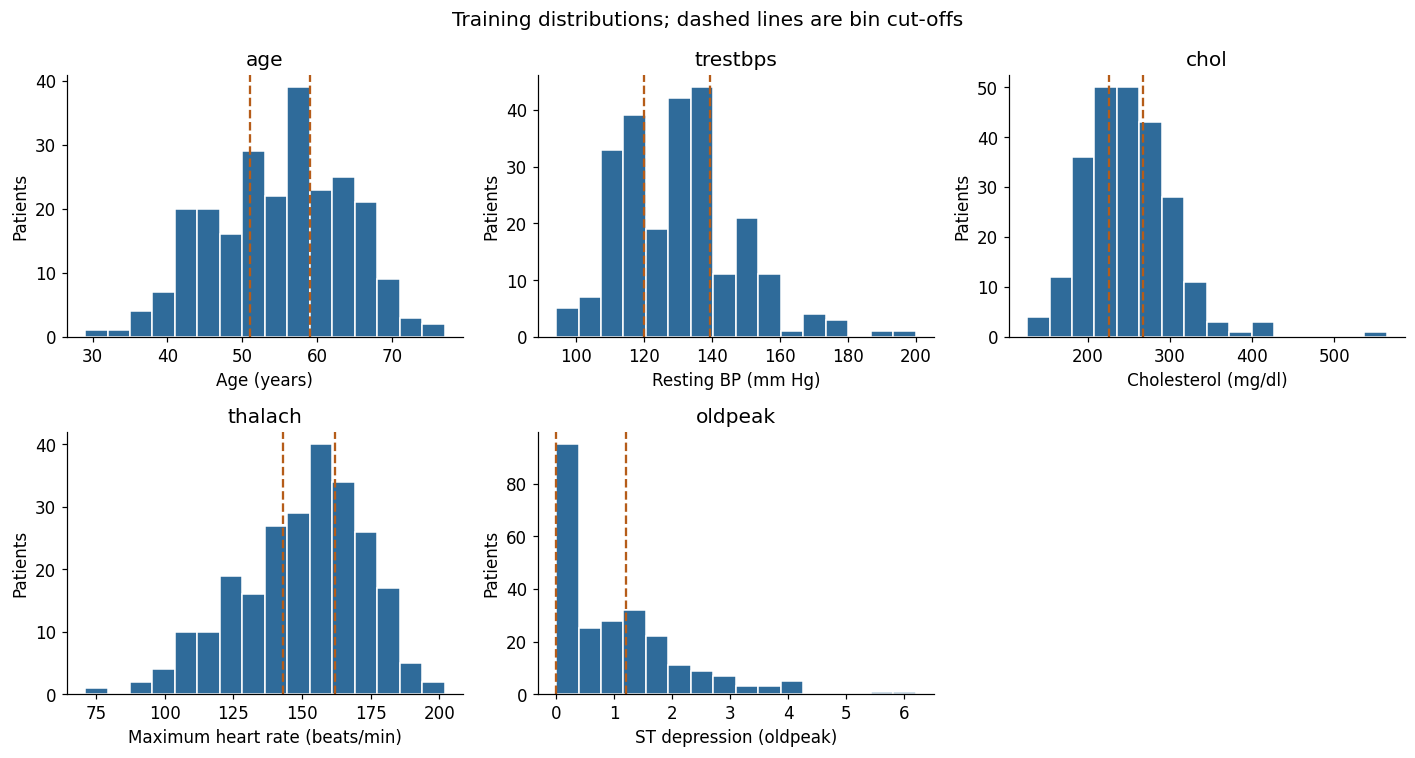

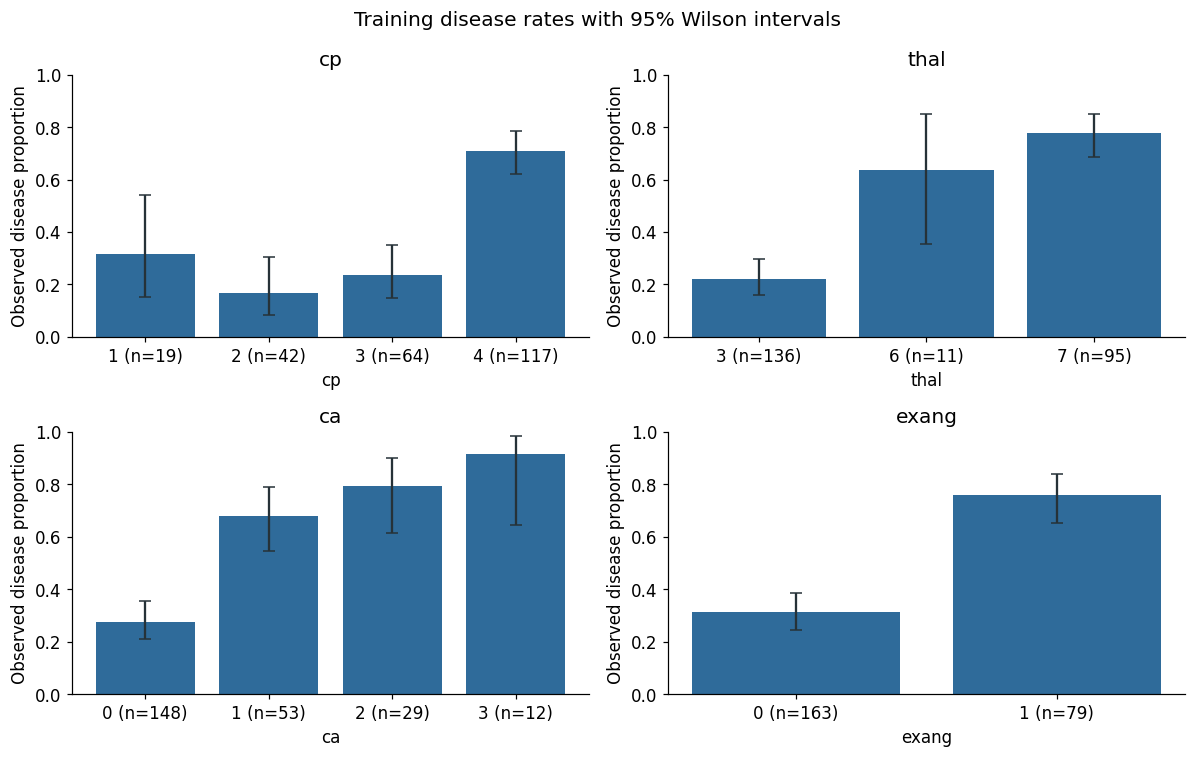

,Mutual information (nats)
thal,0.1560
cp,0.1272
ca,0.1161
exang,0.0911
thalach_cat,0.0731
slope,0.0706
oldpeak_cat,0.0567
sex,0.0496
age_cat,0.0252
restecg,0.0155


The largest univariate mutual information is for **thal** (0.156 nats). This measures association, not causation or independent predictive value. Small category groups have wider uncertainty. Cholesterol has a long upper tail; valid unusual values are retained rather than removed to improve scores.

In [ ]:
fig, axes = plt.subplots(2,3,figsize=(13,7))
units = ['Age (years)','Resting BP (mm Hg)','Cholesterol (mg/dl)','Maximum heart rate (beats/min)','ST depression (oldpeak)']
for ax,c,label in zip(axes.flat,continuous,units):
    ax.hist(train_imputed[c],bins=16,color='#2F6B9A',edgecolor='white')
    for cut in bin_specs[c]['edges'][1:-1]: ax.axvline(cut,color='#B55C19',linestyle='--')
    ax.set(xlabel=label,ylabel='Patients',title=c)
axes.flat[-1].axis('off'); fig.suptitle('Training distributions; dashed lines are bin cut-offs')
plt.tight_layout(); plt.show()
rate_tables=[]
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,c in zip(axes.flat,['cp','thal','ca','exang']):
    group=train.groupby(c)[TARGET].agg(['mean','size','sum'])
    # Wilson intervals describe uncertainty in an unadjusted binomial proportion.
    p,n=group['mean'].to_numpy(),group['size'].to_numpy(); z=1.96
    centre=(p+z*z/(2*n))/(1+z*z/n); half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    ax.bar(np.arange(len(group)),p,color='#2F6B9A')
    ax.errorbar(np.arange(len(group)),centre,yerr=half,fmt='none',color='#263238',capsize=4)
    ax.set_xticks(np.arange(len(group)),[f'{v} (n={int(k)})' for v,k in zip(group.index,n)])
    ax.set(ylim=(0,1),xlabel=c,ylabel='Observed disease proportion',title=c)
    rate_tables.append(group.assign(variable=c).reset_index())
fig.suptitle('Training disease rates with 95% Wilson intervals')
plt.tight_layout(); plt.show()
mi=pd.Series({c:mutual_info_score(train[c],train[TARGET]) for c in NODES if c!=TARGET}).sort_values(ascending=False)
display(mi.rename('Mutual information (nats)').to_frame())
display(Markdown(f'The largest univariate mutual information is for **{mi.index[0]}** ({mi.iloc[0]:.3f} nats). This measures association, not causation or independent predictive value. Small category groups have wider uncertainty. Cholesterol has a long upper tail; valid unusual values are retained rather than removed to improve scores.'))

## 4. Expert DAG: preserve the proposed clinical structure
The expert graph keeps the original notebook's 21 arrows and all 14 nodes. Age and baseline risk measurements point towards disease; disease points towards symptoms and test findings. Evidence can update disease probability even when the arrow points from disease towards the observed finding: inference is not restricted to following arrow direction.

Every edge is justified below. Some directions express a plausible ordering, while others simply allow related measurements to remain dependent. These assumptions are not claims that this dataset has identified causal mechanisms.

In [ ]:
# These names must exactly match the final discrete modelling data.
EXPERT_NODES = [
    "age_cat",
    "sex",
    "cp",
    "trestbps_cat",
    "chol_cat",
    "fbs",
    "restecg",
    "thalach_cat",
    "exang",
    "oldpeak_cat",
    "slope",
    "ca",
    "thal",
    "heartdisease_bin"
]


# Each tuple is: (parent, child)
# Preserve the original notebook's proposed expert structure.
EXPERT_EDGES = [
    # Age-related dependencies
    ("age_cat", "trestbps_cat"),
    ("age_cat", "fbs"),
    ("age_cat", "chol_cat"),
    ("age_cat", "heartdisease_bin"),
    ("age_cat", "thalach_cat"),

    # Risk factors and related resting measurements
    ("trestbps_cat", "heartdisease_bin"),
    ("trestbps_cat", "restecg"),
    ("fbs", "heartdisease_bin"),
    ("chol_cat", "heartdisease_bin"),
    ("sex", "heartdisease_bin"),

    # Disease-conditioned diagnostic findings
    ("heartdisease_bin", "thalach_cat"),
    ("heartdisease_bin", "cp"),
    ("heartdisease_bin", "restecg"),
    ("heartdisease_bin", "thal"),
    ("heartdisease_bin", "ca"),
    ("heartdisease_bin", "exang"),
    ("heartdisease_bin", "oldpeak_cat"),
    ("heartdisease_bin", "slope"),

    # Selected dependencies among related findings
    ("cp", "exang"),
    ("exang", "oldpeak_cat"),
    ("oldpeak_cat", "slope")
]

assert len(EXPERT_NODES) == 14
assert len(EXPERT_EDGES) == 21

The following rationales are modelling judgements. The assignment/UCI codebook establishes what each measurement means. [Detrano et al. (1989)](https://pubmed.ncbi.nlm.nih.gov/2756873/) supports studying clinical and test information together, but does not validate these exact arrows. [Tanaka et al. (2001)](https://pubmed.ncbi.nlm.nih.gov/11153730/) supports the age–maximum-heart-rate relationship. The [2019 ACC/AHA prevention guideline](https://www.ahajournals.org/doi/10.1161/CIR.0000000000000678) provides background for cardiovascular risk factors, not proof of this DAG.

In [ ]:
rationales = ['Allow the blood-pressure distribution to vary with age.', 'Allow the high-glucose indicator to vary with age; it is not a diabetes diagnosis.', 'Allow cholesterol to vary across age groups without assuming a monotonic effect.', 'Age provides baseline information about disease probability.', 'Maximum achievable heart rate is related to age (Tanaka et al.).', 'Blood pressure contributes baseline cardiovascular risk information.', 'Resting ECG includes hypertrophy, making dependence on blood pressure plausible.', 'The high-glucose indicator is a limited proxy for metabolic risk.', 'Cholesterol contributes baseline cardiovascular risk information.', 'The sex code allows different baseline disease distributions.', 'Disease status may help explain the achieved exercise heart rate.', 'Chest-pain type is a diagnostic finding whose distribution may depend on disease.', 'Resting ECG findings may differ by disease status; normal ECG does not imply no disease.', 'Perfusion-test findings provide diagnostic information about disease.', 'Fluoroscopic vessel information and the target are linked to the diagnostic investigation; timing limits screening use.', 'Exercise-induced angina may be associated with disease.', 'Exercise ST depression may be associated with disease.', 'Exercise ST slope may be associated with disease.', 'Chest-pain type and exercise angina describe related symptoms; direction is a factorisation choice.', 'Angina and ST depression are related exercise-test observations; direction is an assumption.', 'ST-depression magnitude and slope come from the same exercise response; direction is an assumption.']
edge_notes = pd.DataFrame([(a,b,r) for (a,b),r in zip(EXPERT_EDGES,rationales)], columns=['Parent','Child','Rationale'])
assert len(edge_notes)==len(EXPERT_EDGES)==21
display(HTML(edge_notes.to_html(index=False)))
expert_graph=nx.DiGraph(); expert_graph.add_nodes_from(NODES); expert_graph.add_edges_from(EXPERT_EDGES)
assert nx.is_directed_acyclic_graph(expert_graph)

Parent,Child,Rationale
age_cat,trestbps_cat,Allow the blood-pressure distribution to vary with age.
age_cat,fbs,Allow the high-glucose indicator to vary with age; it is not a diabetes diagnosis.
age_cat,chol_cat,Allow cholesterol to vary across age groups without assuming a monotonic effect.
age_cat,heartdisease_bin,Age provides baseline information about disease probability.
age_cat,thalach_cat,Maximum achievable heart rate is related to age (Tanaka et al.).
trestbps_cat,heartdisease_bin,Blood pressure contributes baseline cardiovascular risk information.
trestbps_cat,restecg,"Resting ECG includes hypertrophy, making dependence on blood pressure plausible."
fbs,heartdisease_bin,The high-glucose indicator is a limited proxy for metabolic risk.
chol_cat,heartdisease_bin,Cholesterol contributes baseline cardiovascular risk information.
sex,heartdisease_bin,The sex code allows different baseline disease distributions.


### Learn the second DAG using bnlearn
**Hill climbing** adds, removes or reverses arrows when that improves its score. **BIC** rewards fit and penalises extra parameters, which is useful with only 242 training records. We use the original notebook's unconstrained HC+BIC approach, an empty starting graph and no forced clinical directions. The search can stop at a local optimum, and equally scoring graphs can differ in orientation. A learned arrow is therefore an observational dependency, not a proven cause.

The explicit limits below make the settings inspectable. Neither test labels nor test performance selects the structure.

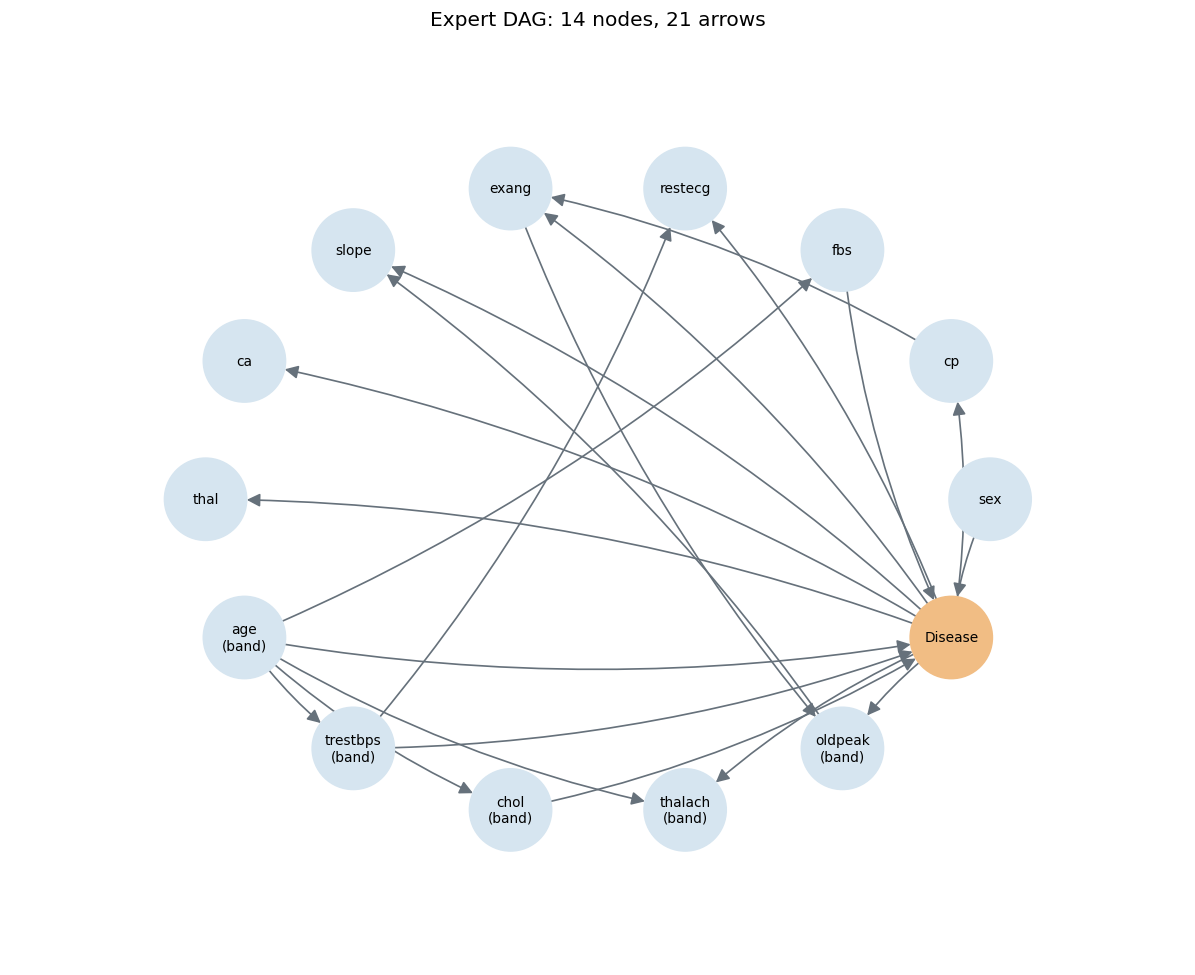

,Parent,Child
0,age_cat,chol_cat
1,age_cat,fbs
2,age_cat,heartdisease_bin
3,age_cat,thalach_cat
4,age_cat,trestbps_cat
5,chol_cat,heartdisease_bin
6,cp,exang
7,exang,oldpeak_cat
8,fbs,heartdisease_bin
9,heartdisease_bin,ca


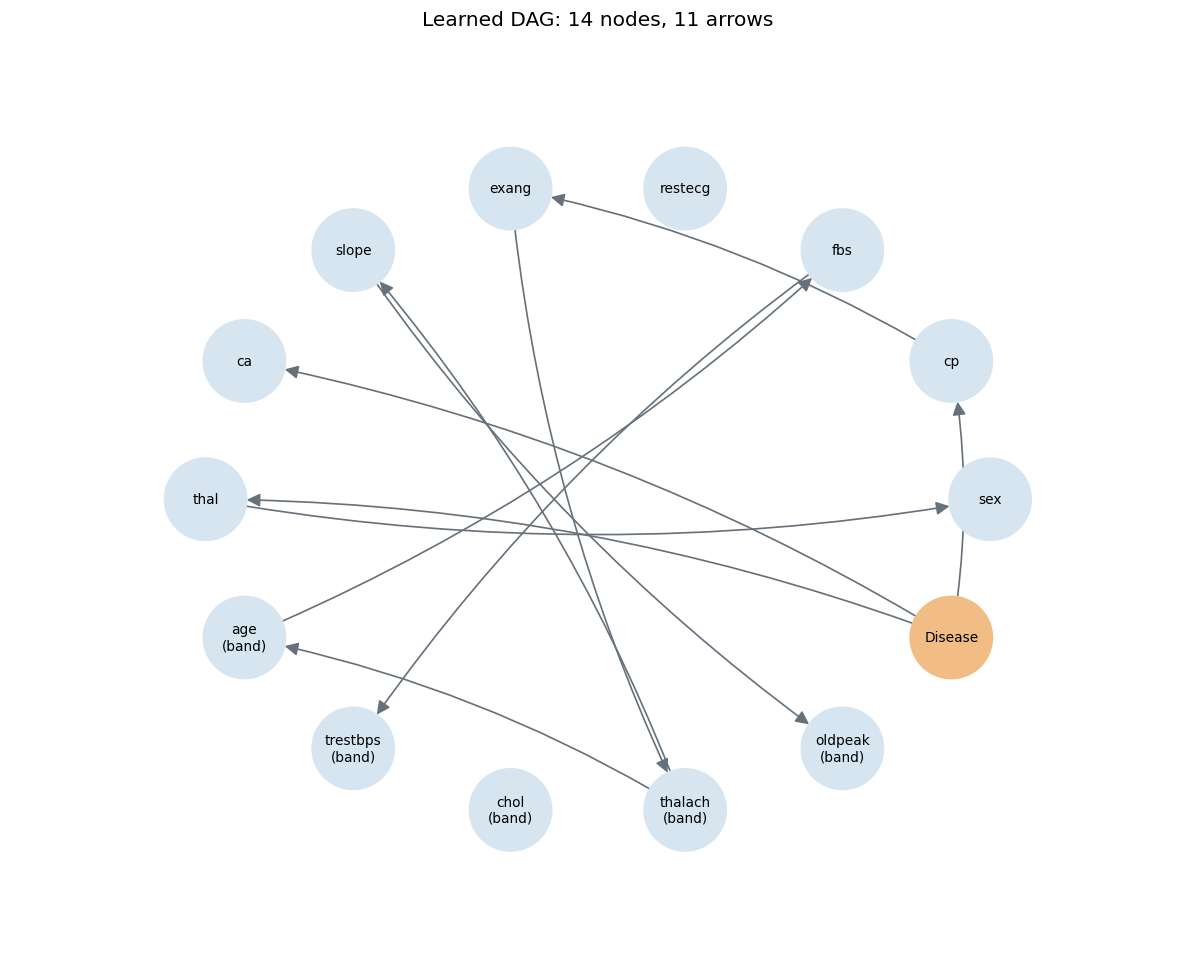

,Parent,Child
0,age_cat,fbs
1,cp,exang
2,exang,thalach_cat
3,fbs,trestbps_cat
4,heartdisease_bin,ca
5,heartdisease_bin,cp
6,heartdisease_bin,thal
7,slope,oldpeak_cat
8,thal,sex
9,thalach_cat,age_cat


In [ ]:
learned_result=bn.structure_learning.fit(train, methodtype='hc', scoretype='bic',
    max_indegree=None, tabu_length=100, epsilon=1e-4, max_iter=10000, verbose=0)
learned_graph=nx.DiGraph()
learned_graph.add_nodes_from(NODES)
learned_graph.add_edges_from(learned_result['model'].edges())
assert set(learned_result['model'].nodes())==set(NODES)
assert nx.is_directed_acyclic_graph(learned_graph)
graphs={'Expert':expert_graph,'Learned':learned_graph}
positions=nx.circular_layout(NODES)
labels={n:n.replace('heartdisease_bin','Disease').replace('_cat','\n(band)') for n in NODES}
for name,g in graphs.items():
    fig,ax=plt.subplots(figsize=(11,9))
    nx.draw_networkx(g,pos=positions,labels=labels,ax=ax,node_size=2900,font_size=9,
        node_color=['#F1BD84' if n==TARGET else '#D6E5F0' for n in g.nodes()],
        arrowsize=18,width=1.1,edge_color='#66717B',connectionstyle='arc3,rad=0.09')
    ax.set_title(f'{name} DAG: {g.number_of_nodes()} nodes, {g.number_of_edges()} arrows')
    ax.margins(.18); ax.axis('off'); plt.tight_layout(); plt.show()
    display(pd.DataFrame(sorted(g.edges()),columns=['Parent','Child']))

### Compare common, unique and reversed edges
Reversed pairs are listed separately and excluded from the unique-edge categories. This avoids counting an arrow twice. A **Markov blanket** contains the target's parents, children and children's other parents. Given all these variables, other nodes provide no extra information about the target within that fitted graph.

In [ ]:
def blanket(g,node):
    parents=set(g.predecessors(node)); children=set(g.successors(node))
    return (parents|children|{p for child in children for p in g.predecessors(child)})-{node}
e,l=set(expert_graph.edges()),set(learned_graph.edges())
common=e&l; reversed_e={edge for edge in e if edge[::-1] in l}
only_e=e-common-reversed_e; only_l=l-common-{x[::-1] for x in reversed_e}
assert len(e)==len(common)+len(reversed_e)+len(only_e)
assert len(l)==len(common)+len(reversed_e)+len(only_l)
for title,edges in [('Common',common),('Reversed (expert direction shown)',reversed_e),('Expert only',only_e),('Learned only',only_l)]:
    display(Markdown(f'**{title}: {len(edges)}**')); display(pd.DataFrame(sorted(edges),columns=['Parent','Child']))
for name,g in graphs.items(): print(name,'target Markov blanket:', sorted(blanket(g,TARGET)))
strange=[(a,b) for a,b in l if b in ['sex','age_cat']]
display(Markdown(f'There are **{len(common)} common directed edges** and **{len(reversed_e)} reversed pairs**. The expert graph has {len(e)} edges; the learned graph has {len(l)}. Learned arrows into age or sex are **{strange}**. Later test results cannot change a patient’s recorded age or sex: these arrows are statistical factorisations, not credible intervention pathways. Expert-only edges may be too weak or costly under BIC in this small sample. Learned-only edges can represent proxy relationships or sampling variation. Neither inclusion nor omission proves a biological mechanism.'))

**Common: 5**

,Parent,Child
0,age_cat,fbs
1,cp,exang
2,heartdisease_bin,ca
3,heartdisease_bin,cp
4,heartdisease_bin,thal


**Reversed (expert direction shown): 2**

,Parent,Child
0,age_cat,thalach_cat
1,oldpeak_cat,slope


**Expert only: 14**

,Parent,Child
0,age_cat,chol_cat
1,age_cat,heartdisease_bin
2,age_cat,trestbps_cat
3,chol_cat,heartdisease_bin
4,exang,oldpeak_cat
5,fbs,heartdisease_bin
6,heartdisease_bin,exang
7,heartdisease_bin,oldpeak_cat
8,heartdisease_bin,restecg
9,heartdisease_bin,slope


**Learned only: 4**

,Parent,Child
0,exang,thalach_cat
1,fbs,trestbps_cat
2,thal,sex
3,thalach_cat,slope


Expert target Markov blanket: ['age_cat', 'ca', 'chol_cat', 'cp', 'exang', 'fbs', 'oldpeak_cat', 'restecg', 'sex', 'slope', 'thal', 'thalach_cat', 'trestbps_cat']
Learned target Markov blanket: ['ca', 'cp', 'thal']


There are **5 common directed edges** and **2 reversed pairs**. The expert graph has 21 edges; the learned graph has 11. Learned arrows into age or sex are **[('thalach_cat', 'age_cat'), ('thal', 'sex')]**. Later test results cannot change a patient’s recorded age or sex: these arrows are statistical factorisations, not credible intervention pathways. Expert-only edges may be too weak or costly under BIC in this small sample. Learned-only edges can represent proxy relationships or sampling variation. Neither inclusion nor omission proves a biological mechanism.

### What the structural differences mean
In this run, `age_cat → thalach_cat` is reversed: achieved heart rate cannot cause age. The `oldpeak_cat → slope` reversal involves two summaries of the same exercise ECG; their association is more defensible than either causal direction. The learned-only `thal → sex` arrow is another clear reason not to read this graph causally. `exang → thalach_cat` and `thalach_cat → slope` link exercise-test findings; shared physiology or test conditions could explain them. `fbs → trestbps_cat` can reflect correlated metabolic measurements, but these data do not establish a glucose intervention effect.

The learned target's Markov blanket is only `cp`, `thal` and `ca` in this fitted graph. Once these are known, changing the other predictors should not change its disease posterior, apart from numerical rounding. This explains why many grid profiles tie and why adding evidence can affect the expert model more strongly. These statements describe the displayed run; equally scoring HC solutions can have different orientations across software environments. The saved models and state schema preserve this exact fitted result.

## 5. Parameter learning and CPT checks
**BDeu** adds a uniform Dirichlet prior before normalising counts. ESS = 5 spreads five pseudo-observations across each node's entire CPT. For a node with `r` states and `q` parent configurations, each cell receives `5/(r*q)`. A configuration absent from training therefore receives a uniform conditional distribution. This is a prior assumption, not evidence from patients.

The original notebook's fitted learned model lost isolated nodes. Here we construct a fresh BayesianNetwork, add **all nodes explicitly**, then add the edges and CPTs. An isolated node still needs an unconditional probability table. We check graph equality, one CPT per node, probabilities summing to one, and finite positive values.

In [ ]:
def fit_parameters(graph, ess=ESS):
    model=BayesianNetwork()
    model.add_nodes_from(NODES); model.add_edges_from(graph.edges())
    estimator=BayesianEstimator(model,train,state_names=STATES)
    model.add_cpds(*estimator.get_parameters(prior_type='BDeu',equivalent_sample_size=ess,n_jobs=1))
    assert set(model.nodes())==set(NODES)
    assert set(model.edges())==set(graph.edges())
    assert len(model.get_cpds())==len(NODES)
    assert model.check_model()
    for cpd in model.get_cpds():
        a=cpd.get_values()
        assert np.isfinite(a).all() and (a>0).all()
        assert np.allclose(a.sum(axis=0),1)
    return model
models={name:fit_parameters(g) for name,g in graphs.items()}
print('PASS: both models retain 14 nodes and 14 valid CPTs.')

def cpt_table(model,node):
    cpd=model.get_cpds(node); parents=list(cpd.variables[1:]); rows=[]
    combinations=list(product(*(cpd.state_names[p] for p in parents)))
    for j,values in enumerate(combinations):
        mask=np.ones(len(train),dtype=bool)
        for p,v in zip(parents,values): mask &= train[p].eq(v).to_numpy()
        row={p:v for p,v in zip(parents,values)}
        row['training_n']=int(mask.sum())
        for i,state in enumerate(cpd.state_names[node]): row[f'P({node}={state})']=float(cpd.get_values()[i,j])
        rows.append(row)
    return pd.DataFrame(rows)

cpts={name:{node:cpt_table(m,node) for node in NODES} for name,m in models.items()}
complexity=[]
for name,m in models.items():
    for node,table in cpts[name].items(): table.to_csv(OUT/f'{name}_CPT_{node}.csv',index=False)
    free=sum((len(STATES[c.variable])-1)*c.get_values().shape[1] for c in m.get_cpds())
    t=cpts[name][TARGET]
    complexity.append({'model':name,'edges':len(m.edges()),'free_parameters':free,
        'target_configurations':len(t),'target_empty':int((t.training_n==0).sum()),
        'target_support_below_5':int((t.training_n<5).sum())})
complexity=pd.DataFrame(complexity).set_index('model'); display(complexity)

PASS: both models retain 14 nodes and 14 valid CPTs.


,edges,free_parameters,target_configurations,target_empty,target_support_below_5
model,,,,,
Expert,21,194,108,39,93
Learned,11,57,1,0,0


### Detailed target CPTs and direct-parent CPTs
Each row is one parent configuration; `training_n` shows how many training patients support it. Both target-state probabilities are included. The expandable tables preserve every row without overwhelming the main report. All 28 node CPTs are also exported as CSV files. A target with no parents has a one-row prior CPT, but its posterior can still change when its children are observed.

In [ ]:
for name,m in models.items():
    key_nodes=[TARGET]+sorted(m.predecessors(TARGET))
    for node in key_nodes:
        table=cpts[name][node]
        display(HTML(f'<details><summary><b>{name}: complete CPT for {node} ({len(table)} configurations)</b></summary>'+table.to_html(index=False,float_format=lambda v:f'{v:.6f}')+'</details>'))
    others=[n for n in NODES if n not in key_nodes]
    display(HTML('<details><summary><b>'+name+': remaining node CPTs</b></summary>'+''.join('<h4>'+n+'</h4>'+cpts[name][n].to_html(index=False,float_format=lambda v:f'{v:.6f}') for n in others)+'</details>'))

age_cat,chol_cat,fbs,sex,trestbps_cat,training_n,P(heartdisease_bin=0),P(heartdisease_bin=1)
High,High,0,0,High,11,0.726320,0.273680
High,High,0,0,Low,3,0.664134,0.335866
High,High,0,0,Medium,2,0.500000,0.500000
High,High,0,1,High,5,0.004587,0.995413
High,High,0,1,Low,4,0.500000,0.500000
High,High,0,1,Medium,2,0.011312,0.988688
High,High,1,0,High,1,0.977876,0.022124
High,High,1,0,Low,0,0.500000,0.500000
High,High,1,0,Medium,1,0.022124,0.977876
High,High,1,1,High,1,0.022124,0.977876


training_n,P(age_cat=High),P(age_cat=Low),P(age_cat=Medium)
242,0.302294,0.354926,0.342780


age_cat,training_n,P(chol_cat=High),P(chol_cat=Low),P(chol_cat=Medium)
High,73,0.436012,0.261905,0.302083
Low,86,0.234474,0.428390,0.337136
Medium,83,0.349081,0.337270,0.313648


age_cat,training_n,P(fbs=0),P(fbs=1)
High,73,0.828125,0.171875
Low,86,0.944867,0.055133
Medium,83,0.765748,0.234252


training_n,P(sex=0),P(sex=1)
242,0.321862,0.678138


age_cat,training_n,P(trestbps_cat=High),P(trestbps_cat=Low),P(trestbps_cat=Medium)
High,73,0.489583,0.275298,0.235119
Low,86,0.200253,0.485425,0.314322
Medium,83,0.337270,0.266404,0.396325


training_n,P(heartdisease_bin=0),P(heartdisease_bin=1)
242,0.540486,0.459514


### Interpret at least five informative CPT patterns
We select five supported target-CPT rows in each model where possible, ranked by distance from the training prevalence. Selection is descriptive and does not imply a significance test. At least five training patients are preferred, but this is still a small sample. If the learned target is a root node, its single prior row is explained and additional diagnostic-node CPT patterns are shown. `P(test finding | disease)` is not the same quantity as `P(disease | test finding)`.

In [ ]:
prevalence=float(y_train.mean())
for name,m in models.items():
    t=cpts[name][TARGET].copy(); pcol=f'P({TARGET}=1)'
    if len(t)==1:
        display(Markdown(f'**{name}:** the target prior is {t[pcol].iloc[0]:.1%}, based on {t.training_n.iloc[0]} patients. Clinical evidence updates this prior through connected nodes during inference.'))
    else:
        supported=t[t.training_n>=5].copy()
        supported['distance']=(supported[pcol]-prevalence).abs()
        selected=supported.sort_values('distance',ascending=False).head(5)
        assert len(selected)>=5
        for _,r in selected.iterrows():
            config=', '.join(f'{p}={r[p]}' for p in m.predecessors(TARGET))
            display(Markdown(f'- **{name}, {config}:** P(disease) = **{r[pcol]:.1%}**, versus training prevalence {prevalence:.1%}; support = {int(r.training_n)} patients. The difference is {(r[pcol]-prevalence)*100:+.1f} percentage points. This is a conditional association, with substantial small-sample uncertainty.'))
    shown=0
    for node in ['cp','thal','ca','exang','oldpeak_cat']:
        if TARGET in m.get_cpds(node).variables[1:]:
            tnode=cpts[name][node]
            display(Markdown(f'**{name}: {node} conditional on its parents.** Compare the disease states while keeping other parent values fixed. These are probabilities of findings, not diagnostic probabilities.'))
            display(tnode)
            if list(m.get_cpds(node).variables[1:]) == [TARGET]:
                state = {'cp':4,'thal':7,'ca':0}[node]
                col = f'P({node}={state})'
                absent = float(tnode.loc[tnode[TARGET]==0,col].iloc[0])
                present = float(tnode.loc[tnode[TARGET]==1,col].iloc[0])
                display(Markdown(f'For **{name}**, P({node}={state} | disease=1) is **{present:.1%}**, compared with **{absent:.1%}** given disease=0. The difference is {(present-absent)*100:+.1f} percentage points. This describes the distribution of a finding within each disease group.'))
            shown+=1
        if shown==3: break
expert_empty=int(complexity.loc['Expert','target_empty'])
display(Markdown(f'The expert target has **{expert_empty} unobserved parent configurations**. Their 50% disease probabilities arise from the symmetric prior. They must not be described as 50% disease rates measured in patients.'))

- **Expert, sex=1, fbs=0, age_cat=High, trestbps_cat=High, chol_cat=High:** P(disease) = **99.5%**, versus training prevalence 45.9%; support = 5 patients. The difference is +53.7 percentage points. This is a conditional association, with substantial small-sample uncertainty.

- **Expert, sex=1, fbs=0, age_cat=High, trestbps_cat=Low, chol_cat=Medium:** P(disease) = **99.5%**, versus training prevalence 45.9%; support = 5 patients. The difference is +53.7 percentage points. This is a conditional association, with substantial small-sample uncertainty.

- **Expert, sex=0, fbs=0, age_cat=Low, trestbps_cat=Low, chol_cat=Low:** P(disease) = **0.3%**, versus training prevalence 45.9%; support = 9 patients. The difference is -45.6 percentage points. This is a conditional association, with substantial small-sample uncertainty.

- **Expert, sex=1, fbs=0, age_cat=Low, trestbps_cat=Medium, chol_cat=Low:** P(disease) = **0.4%**, versus training prevalence 45.9%; support = 6 patients. The difference is -45.5 percentage points. This is a conditional association, with substantial small-sample uncertainty.

- **Expert, sex=1, fbs=0, age_cat=Medium, trestbps_cat=High, chol_cat=High:** P(disease) = **88.7%**, versus training prevalence 45.9%; support = 9 patients. The difference is +42.8 percentage points. This is a conditional association, with substantial small-sample uncertainty.

...

For **Learned**, P(thal=7 | disease=1) is **65.9%**, compared with **16.4%** given disease=0. The difference is +49.6 percentage points. This describes the distribution of a finding within each disease group.

**Learned: ca conditional on its parents.** Compare the disease states while keeping other parent values fixed. These are probabilities of findings, not diagnostic probabilities.

,heartdisease_bin,training_n,P(ca=0),P(ca=1),P(ca=2),P(ca=3)
0,0,131,0.8062,0.1320,0.0496,0.0122
1,1,111,0.3667,0.3227,0.2081,0.1024


For **Learned**, P(ca=0 | disease=1) is **36.7%**, compared with **80.6%** given disease=0. The difference is -43.9 percentage points. This describes the distribution of a finding within each disease group.

The expert target has **39 unobserved parent configurations**. Their 50% disease probabilities arise from the symmetric prior. They must not be described as 50% disease rates measured in patients.

## 6. Probabilistic inference in both models
**Variable elimination** sums over variables we have not observed. We rank the same explicitly defined clinical evidence space in both networks: all combinations of `sex`, `cp`, `exang`, `thal`, `oldpeak_cat`, `thalach_cat`, `slope` and `ca`. Other predictors are marginalised, not silently fixed.

This search identifies highest and lowest probabilities **within this evidence space**, not among every possible medical circumstance. Many complete combinations have no training records. Their predictions combine learned CPTs and assumptions; extreme probabilities are not certainty. We also show the highest-ranked combinations actually observed in training.

Ranked 5,184 combinations per model; 176 occur in training.


**Expert: Highest**

,sex,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,training_n,Expert
5095,1,4,1,7,High,Low,2,3,1,0.9996
5099,1,4,1,7,High,Low,3,3,0,0.9994
5131,1,4,1,7,Moderate,Low,2,3,0,0.9994
5094,1,4,1,7,High,Low,2,2,7,0.9993
4987,1,4,1,6,High,Low,2,3,0,0.9993


**Expert: Lowest**

,sex,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,training_n,Expert
1052,0,2,1,3,No depression,High,3,0,0,0.0005
1044,0,2,1,3,No depression,High,1,0,0,0.0007
1048,0,2,1,3,No depression,High,2,0,0,0.0011
404,0,1,1,3,No depression,High,3,0,0,0.0014
1076,0,2,1,3,No depression,Medium,3,0,0,0.0014


...

**Learned: Lowest**

,sex,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,training_n,Learned
648,0,2,0,3,High,High,1,0,1,0.032
652,0,2,0,3,High,High,2,0,0,0.032
656,0,2,0,3,High,High,3,0,0,0.032
660,0,2,0,3,High,Low,1,0,0,0.032
664,0,2,0,3,High,Low,2,0,0,0.032


**Learned: Highest among observed combinations**

,sex,cp,exang,thal,oldpeak_cat,thalach_cat,slope,ca,training_n,Learned
2191,0,4,0,7,High,Medium,2,3,1,0.9879
2195,0,4,0,7,High,Medium,3,3,1,0.9879
2215,0,4,0,7,Moderate,Low,2,3,1,0.9879
4807,1,4,0,7,Moderate,Low,2,3,1,0.9879
4815,1,4,0,7,Moderate,Medium,1,3,1,0.9879


For **Learned**, the maximum is **98.79%** and the minimum is **3.20%** in this grid. Their training supports are 0 and 1 respectively. Tables give one ordering of tied probabilities; ties can occur when a model ignores some evidence variables.

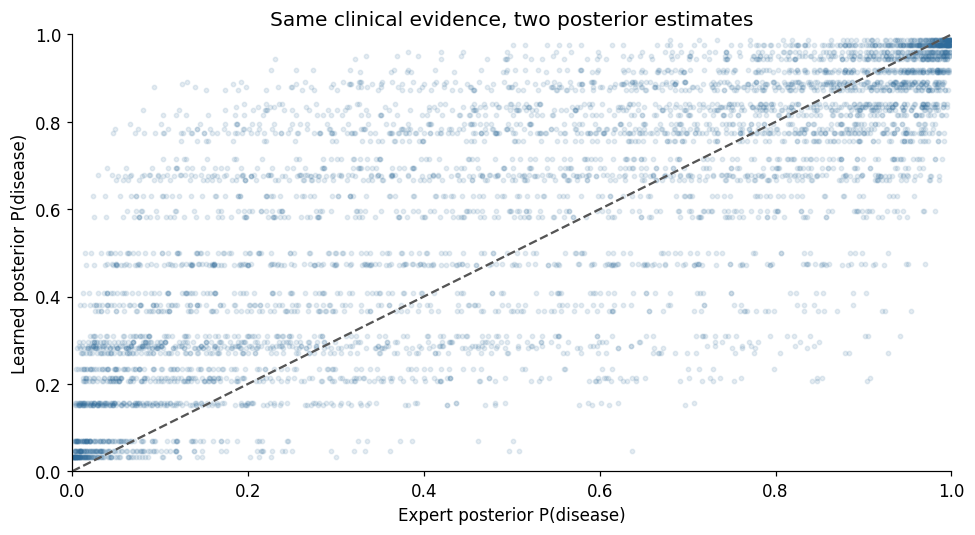

In [ ]:
engines={name:VariableElimination(m) for name,m in models.items()}
def posterior(engine,evidence):
    result=engine.query([TARGET],evidence=evidence,show_progress=False)
    return round(float(result.values[result.state_names[TARGET].index(1)]), 12)
clinical=['sex','cp','exang','thal','oldpeak_cat','thalach_cat','slope','ca']
# Obtain a joint marginal once, then normalise each evidence slice. This is
# algebraically the same P(target,evidence)/P(evidence) as repeated queries.
combinations=list(product(*(STATES[c] for c in clinical)))
ranked=pd.DataFrame(combinations,columns=clinical)
support=train.groupby(clinical,observed=True).size()
ranked['training_n']=[int(support.get(tuple(row),0)) for row in combinations]
for name,engine in engines.items():
    joint=engine.query([TARGET]+clinical,show_progress=False)
    order=[joint.variables.index(v) for v in [TARGET]+clinical]
    values=np.transpose(joint.values,axes=order)
    # Reorder factor axes to match our explicit state schema before flattening.
    for axis,var in enumerate([TARGET]+clinical):
        indices=[joint.state_names[var].index(s) for s in STATES[var]]
        values=np.take(values,indices,axis=axis)
    disease_axis=STATES[TARGET].index(1)
    probs=values[disease_axis]/values.sum(axis=0)
    ranked[name]=np.round(probs.ravel(), 12)
    assert ranked[name].between(0,1).all()
    # Independent execution path for selected rows verifies axis/state alignment.
    for i in [0,len(ranked)//2,len(ranked)-1,int(ranked[name].idxmax()),int(ranked[name].idxmin())]:
        ev={v:ranked.loc[i,v] for v in clinical}
        assert np.isclose(ranked.loc[i,name],posterior(engine,ev),atol=1e-10)
print(f'Ranked {len(ranked):,} combinations per model; {(ranked.training_n>0).sum()} occur in training.')
ranked.to_csv(OUT/'all_clinical_combinations.csv',index=False)
for name in models:
    for title,table in [('Highest',ranked.nlargest(5,name)),('Lowest',ranked.nsmallest(5,name)),
                        ('Highest among observed combinations',ranked[ranked.training_n>0].nlargest(5,name))]:
        display(Markdown(f'**{name}: {title}**')); display(table[clinical+['training_n',name]])
    hi,lo=ranked.loc[ranked[name].idxmax()],ranked.loc[ranked[name].idxmin()]
    display(Markdown(f'For **{name}**, the maximum is **{hi[name]:.2%}** and the minimum is **{lo[name]:.2%}** in this grid. Their training supports are {int(hi.training_n)} and {int(lo.training_n)} respectively. Tables give one ordering of tied probabilities; ties can occur when a model ignores some evidence variables.'))
fig,ax=plt.subplots()
ax.scatter(ranked.Expert,ranked.Learned,s=8,alpha=.12,color='#2F6B9A')
ax.plot([0,1],[0,1],'--',color='#555555')
ax.set(xlabel='Expert posterior P(disease)',ylabel='Learned posterior P(disease)',title='Same clinical evidence, two posterior estimates',xlim=(0,1),ylim=(0,1))
plt.tight_layout(); plt.show()

### Change one clinical variable and hold the others constant
The baseline is the most common complete clinical profile in the training data. Each row changes exactly one variable and leaves the other seven at baseline. We report the change in **percentage points**. These are conditional comparisons, not predictions of what a treatment would cause.

In [ ]:
base_tuple=support.idxmax(); baseline=dict(zip(clinical,base_tuple))
print('Baseline evidence:',baseline,'; training support:',int(support.max()))
one_change=[]
for name,engine in engines.items():
    base_p=posterior(engine,baseline)
    for var in clinical:
        for state in STATES[var]:
            ev=dict(baseline); ev[var]=state; prob=posterior(engine,ev)
            one_change.append({'model':name,'changed_variable':var,'new_state':state,'baseline_state':baseline[var],
                               'baseline_probability':base_p,'posterior':prob,'change_pp':100*(prob-base_p)})
one_change=pd.DataFrame(one_change); display(one_change)
one_change.to_csv(OUT/'one_variable_changes.csv',index=False)
for name in models:
    r=one_change[one_change.model==name].iloc[one_change.loc[one_change.model==name,'change_pp'].abs().to_numpy().argmax()]
    display(Markdown(f"For **{name}**, the largest absolute change from this baseline is changing **{r.changed_variable}** from {r.baseline_state} to {r.new_state}: {r.baseline_probability:.1%} → {r.posterior:.1%} ({r.change_pp:+.1f} percentage points). The conclusion applies to this baseline only."))

Baseline evidence: {'sex': np.int64(1), 'cp': np.int64(2), 'exang': np.int64(0), 'thal': np.int64(3), 'oldpeak_cat': 'No depression', 'thalach_cat': 'High', 'slope': np.int64(1), 'ca': np.int64(0)} ; training support: 7


,model,changed_variable,new_state,baseline_state,baseline_probability,posterior,change_pp
0,Expert,sex,0,1,0.0108,0.0030,-0.7808
1,Expert,sex,1,1,0.0108,0.0108,0.0000
2,Expert,cp,1,2,0.0108,0.0250,1.4187
3,Expert,cp,2,2,0.0108,0.0108,0.0000
4,Expert,cp,3,2,0.0108,0.0125,0.1739
5,Expert,cp,4,2,0.0108,0.0527,4.1913
6,Expert,exang,0,0,0.0108,0.0108,0.0000
7,Expert,exang,1,0,0.0108,0.0027,-0.8131
8,Expert,thal,3,3,0.0108,0.0108,0.0000
9,Expert,thal,6,3,0.0108,0.0578,4.6982


For **Expert**, the largest absolute change from this baseline is changing **ca** from 0 to 3: 1.1% → 16.8% (+15.7 percentage points). The conclusion applies to this baseline only.

For **Learned**, the largest absolute change from this baseline is changing **ca** from 0 to 3: 3.2% → 37.9% (+34.7 percentage points). The conclusion applies to this baseline only.

### Reverse inference: findings among patients with disease
Now we observe `heartdisease_bin = 1` and ask about chest-pain type, perfusion findings, exercise angina and fluoroscopy. We also show the disease-absent distributions for context. These answers describe the fitted model's expected findings given disease; they do not tell us the probability of disease given a finding.

,model,disease,variable,state,probability
0,Expert,0,cp,1,0.1021
1,Expert,0,cp,2,0.2669
2,Expert,0,cp,3,0.3717
3,Expert,0,cp,4,0.2594
4,Expert,0,thal,3,0.8002
5,Expert,0,thal,6,0.0362
6,Expert,0,thal,7,0.1635
7,Expert,0,exang,0,0.8483
8,Expert,0,exang,1,0.1517
9,Expert,0,ca,0,0.8062


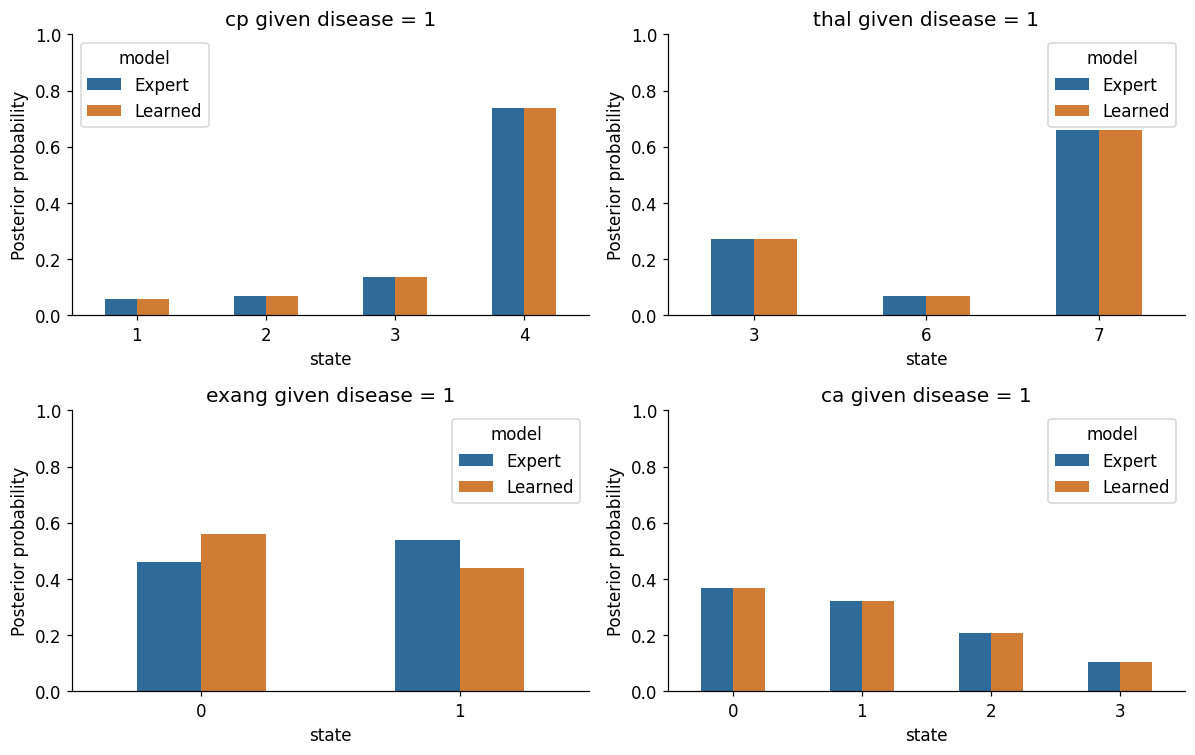

**Expert:** among modelled disease-positive patients, the most probable cp state is **4**, with probability **73.7%**.

**Expert:** among modelled disease-positive patients, the most probable thal state is **7**, with probability **65.9%**.

**Expert:** among modelled disease-positive patients, the most probable exang state is **1**, with probability **54.0%**.

**Expert:** among modelled disease-positive patients, the most probable ca state is **0**, with probability **36.7%**.

**Learned:** among modelled disease-positive patients, the most probable cp state is **4**, with probability **73.7%**.

**Learned:** among modelled disease-positive patients, the most probable thal state is **7**, with probability **65.9%**.

**Learned:** among modelled disease-positive patients, the most probable exang state is **0**, with probability **56.0%**.

**Learned:** among modelled disease-positive patients, the most probable ca state is **0**, with probability **36.7%**.

In [ ]:
reverse=[]
for name,engine in engines.items():
    for outcome in [0,1]:
        for var in ['cp','thal','exang','ca']:
            q=engine.query([var],evidence={TARGET:outcome},show_progress=False)
            for s,p in zip(q.state_names[var],q.values):
                reverse.append({'model':name,'disease':outcome,'variable':var,'state':s,'probability':float(p)})
reverse=pd.DataFrame(reverse); display(reverse)
assert np.allclose(reverse.groupby(['model','disease','variable']).probability.sum(),1)
fig,axes=plt.subplots(2,2,figsize=(11,7))
for var,ax in zip(['cp','thal','exang','ca'],axes.flat):
    pivot=reverse[(reverse.variable==var)&(reverse.disease==1)].pivot(index='state',columns='model',values='probability')
    pivot.plot.bar(ax=ax,color=['#2F6B9A','#D17C35'],rot=0)
    ax.set(title=f'{var} given disease = 1',ylabel='Posterior probability',ylim=(0,1))
plt.tight_layout(); plt.show()
for name in models:
    for var in ['cp','thal','exang','ca']:
        part=reverse[(reverse.model==name)&(reverse.variable==var)&(reverse.disease==1)]
        r=part.loc[part.probability.idxmax()]
        display(Markdown(f'**{name}:** among modelled disease-positive patients, the most probable {var} state is **{r.state}**, with probability **{r.probability:.1%}**.'))

### Are the inference results reasonable?
Both models associate a reversible perfusion defect (`thal=7`) and certain vessel findings with high disease probabilities. However, `cp=4` means the recorded chest-pain category is asymptomatic; it does **not** mean the patient is free of disease. Its strong association in this selected clinical sample should not be generalised to asymptomatic people in the population.

The two models give the same disease-conditional distributions for `cp`, `thal` and `ca` because these nodes have the same target-only parent structure and training counts. They differ for `exang`: the expert model conditions it on disease and chest-pain type, while the learned model reaches it through chest-pain type. Also, `ca=0` is the most frequent individual category among disease-positive patients, even though larger `ca` values are associated with higher disease rates. This is possible because a common category can contain more cases while having a lower proportion of cases. It illustrates why reverse conditional probabilities must not be confused with diagnostic probabilities.

### Prior sensitivity without using the test set
The expert target has many parent combinations and little support per combination. We refit CPTs at ESS 1, 5 and 10 with both structures fixed, then repeat inference for the same baseline and each model's highest/lowest grid profile. This measures dependence on smoothing; it is not a confidence interval. ESS is not selected using the test results.

In [ ]:
sensitivity=[]
profiles={'baseline':baseline}
for name in models:
    for label,idx in [('high',ranked[name].idxmax()),('low',ranked[name].idxmin())]:
        profiles[name+' '+label]={v:ranked.loc[idx,v] for v in clinical}
for name,g in graphs.items():
    for ess in [1,5,10]:
        engine=VariableElimination(fit_parameters(g,ess))
        for label,ev in profiles.items():
            sensitivity.append({'model':name,'ESS':ess,'profile':label,'P(disease)':posterior(engine,ev)})
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity.pivot(index=['model','profile'],columns='ESS',values='P(disease)'))
print('The primary analysis remains ESS = 5 regardless of these differences.')
for name in models:
    sub=sensitivity[sensitivity.model==name]
    spans=sub.groupby('profile')['P(disease)'].agg(lambda x:100*(x.max()-x.min()))
    display(Markdown(f'For **{name}**, the largest posterior range across ESS 1, 5 and 10 is **{spans.max():.2f} percentage points**, for the **{spans.idxmax()}** profile. This checks five selected profiles, not every possible prediction.'))

ESS                           1       5       10
model   profile                                 
Expert  Expert high   9.9977e-01  0.9996  0.9995
        Expert low    2.2797e-05  0.0005  0.0015
        Learned high  7.6400e-01  0.7132  0.6695
        Learned low   1.9405e-03  0.0022  0.0026
        baseline      1.0208e-02  0.0108  0.0116
Learned Expert high   9.9155e-01  0.9879  0.9835
        Expert low    2.9858e-02  0.0320  0.0347
        Learned high  9.9155e-01  0.9879  0.9835
        Learned low   2.9858e-02  0.0320  0.0347
        baseline      2.9858e-02  0.0320  0.0347

The primary analysis remains ESS = 5 regardless of these differences.


For **Expert**, the largest posterior range across ESS 1, 5 and 10 is **9.45 percentage points**, for the **Learned high** profile. This checks five selected profiles, not every possible prediction.

For **Learned**, the largest posterior range across ESS 1, 5 and 10 is **0.80 percentage points**, for the **Expert high** profile. This checks five selected profiles, not every possible prediction.

## 7. Held-out test evaluation
For each test patient we observe all 13 predictors and infer P(disease). Predictions at or above 0.50 are positive. **Precision** asks how many positive predictions are correct. **Recall (sensitivity)** asks how many disease cases are detected. **F1** balances precision and recall. **Specificity** is the proportion of non-disease cases correctly rejected.

**ROC-AUC** measures ranking across thresholds. **Average precision (AP)** summarises the precision–recall curve; it is not the trapezoidal PR area. **Brier score** measures probability error (lower is better). A majority-class baseline predicts no disease for everyone, using the training class balance. We pre-specify ROC-AUC as the primary ranking comparison and report the other metrics to expose trade-offs.

Posterior scores are rounded to 12 decimal places before ranking metrics. Mathematically identical evidence can otherwise differ by floating-point noise near the last decimal, incorrectly breaking ties in ROC-AUC and AP. This numerical rule is fixed for both models; it is not tuned for performance.

,accuracy,precision,recall,specificity,F1,ROC_AUC,AP,Brier,TN,FP,FN,TP
model,,,,,,,,,,,,
Expert,0.8525,0.8065,0.8929,0.8182,0.8475,0.9394,0.9338,0.1051,27,6,3,25
Learned,0.8689,0.8571,0.8571,0.8788,0.8571,0.9183,0.9137,0.1081,29,4,4,24
Baseline,0.5410,0.0000,0.0000,1.0000,0.0000,0.5000,0.4590,0.2483,33,0,28,0


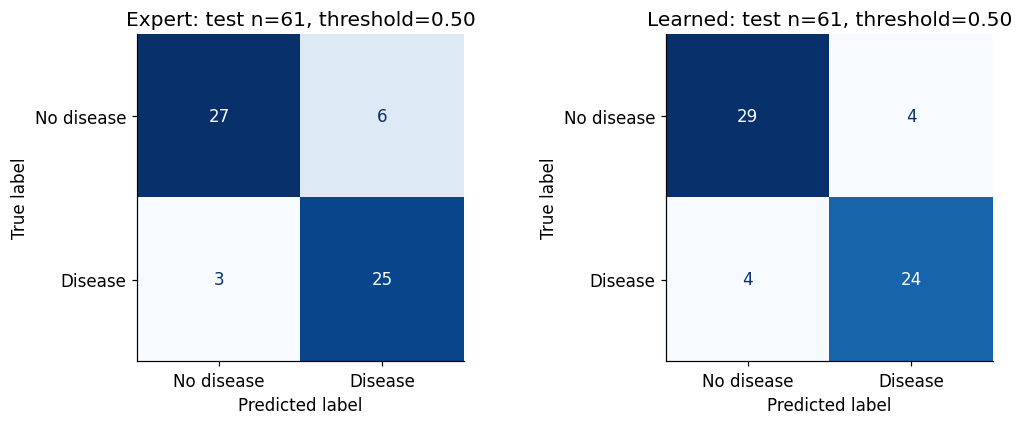

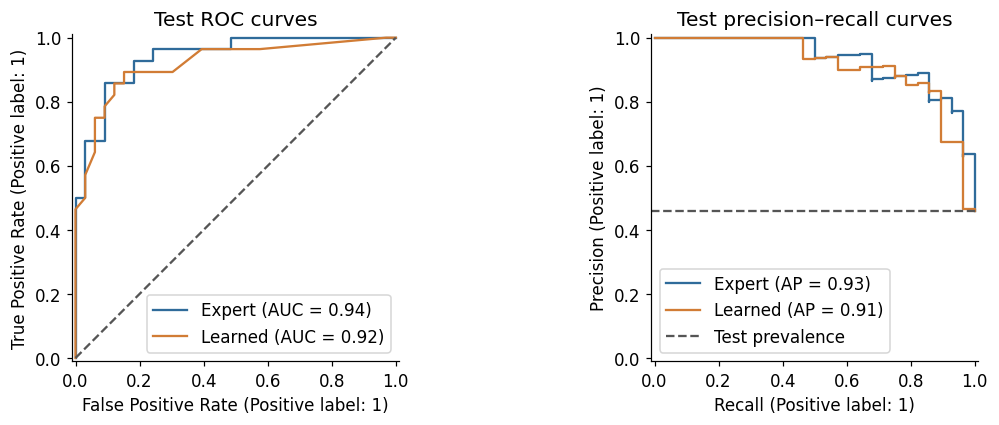

In [ ]:
probabilities={name:np.array([posterior(engine,row.to_dict()) for _,row in test.drop(columns=TARGET).iterrows()])
               for name,engine in engines.items()}
probabilities['Baseline']=np.repeat(prevalence,len(test))
def metric_row(name,p):
    pred=(p>=THRESHOLD).astype(int); tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    return {'model':name,'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),
            'recall':recall_score(y_test,pred),'specificity':tn/(tn+fp),'F1':f1_score(y_test,pred),
            'ROC_AUC':roc_auc_score(y_test,p),'AP':average_precision_score(y_test,p),
            'Brier':brier_score_loss(y_test,p),'TN':tn,'FP':fp,'FN':fn,'TP':tp}
metrics=pd.DataFrame([metric_row(name,p) for name,p in probabilities.items()]).set_index('model')
display(metrics); metrics.to_csv(OUT/'test_metrics.csv')
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,(name,p) in zip(axes,[(n,probabilities[n]) for n in models]):
    ConfusionMatrixDisplay.from_predictions(y_test,p>=THRESHOLD,display_labels=['No disease','Disease'],ax=ax,colorbar=False,cmap='Blues')
    ax.set_title(f'{name}: test n={len(test)}, threshold={THRESHOLD:.2f}')
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,color in [('Expert','#2F6B9A'),('Learned','#D17C35')]:
    RocCurveDisplay.from_predictions(y_test,probabilities[name],name=name,ax=axes[0],color=color)
    PrecisionRecallDisplay.from_predictions(y_test,probabilities[name],name=name,ax=axes[1],color=color)
axes[0].plot([0,1],[0,1],'--',color='#555555'); axes[0].set_title('Test ROC curves')
axes[1].axhline(y_test.mean(),linestyle='--',color='#555555',label='Test prevalence')
axes[1].set_title('Test precision–recall curves'); axes[1].legend()
plt.tight_layout(); plt.show()
prediction_export=test.copy()
for name,p in probabilities.items(): prediction_export[name+'_probability']=p
prediction_export.to_csv(OUT/'test_predictions.csv',index_label='source_row')

### Uncertainty in the comparison
A test set of 61 patients gives an imprecise performance estimate. We bootstrap the same test patients in pairs for both models and calculate the difference in ROC-AUC. The percentile interval describes test-sample uncertainty conditional on these fitted models; it does not include uncertainty from retraining or represent external validation. We do not change the models after seeing the test scores.

In [ ]:
rng=np.random.default_rng(SEED); yy=y_test.to_numpy(); differences=[]
for _ in range(2000):
    idx=rng.integers(0,len(yy),len(yy))
    if len(np.unique(yy[idx]))<2: continue
    differences.append(roc_auc_score(yy[idx],probabilities['Learned'][idx])-roc_auc_score(yy[idx],probabilities['Expert'][idx]))
auc_interval=np.quantile(differences,[.025,.975])
auc_difference=metrics.loc['Learned','ROC_AUC']-metrics.loc['Expert','ROC_AUC']
print(f'Learned minus Expert ROC-AUC: {auc_difference:.3f}; paired bootstrap 95% interval [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
uncertain=auc_interval[0]<=0<=auc_interval[1]
display(Markdown('The interval includes zero, so this test set does not establish a reliable ranking advantage.' if uncertain else 'The interval excludes zero in this conditional comparison, but external validation and retraining uncertainty are still needed.'))

Learned minus Expert ROC-AUC: -0.021; paired bootstrap 95% interval [-0.098, 0.039]


The interval includes zero, so this test set does not establish a reliable ranking advantage.

## 8. Model comparison and reflection
The best predictive model need not be the easiest to explain clinically. Edge count measures structural simplicity; clinically coherent arrow directions are a different aspect of interpretability. The expert model has a clear diagnostic story, but its large target CPT is difficult to estimate. The learned model uses BIC to reduce complexity, but some arrow directions may be clinically implausible if read causally.

**Limitations:** discretisation loses information; mode imputation understates missing-value uncertainty; the expert CPT is sparse; hill climbing may find a local optimum; and one train–test split is unstable. The data contain diagnostic-test measurements, including `ca`. This is a diagnostic classification exercise using those measurements, not a validated pre-test screening tool. Dropping `ca` and retraining would be needed to assess a setting where that test is unavailable. We make no treatment or deployment recommendation.

In [ ]:
winner=metrics.loc[['Expert','Learned'],'ROC_AUC'].idxmax()
for name in models:
    r=metrics.loc[name]
    display(Markdown(f'**{name}:** accuracy {r.accuracy:.1%}, precision {r.precision:.1%}, recall {r.recall:.1%}, F1 {r.F1:.3f}, ROC-AUC {r.ROC_AUC:.3f}, AP {r.AP:.3f}, Brier {r.Brier:.3f}. It misses **{int(r.FN)} of {int(y_test.sum())}** disease cases and incorrectly flags **{int(r.FP)} of {int((y_test==0).sum())}** non-disease cases.'))
display(Markdown(f'**Comparison:** {winner} has the higher observed ROC-AUC on this split. This is a point-estimate comparison, not a claim of universal superiority. The learned model has {complexity.loc["Learned","free_parameters"]} free parameters compared with {complexity.loc["Expert","free_parameters"]} for the expert model. Interpretability depends on both the number of parameters and the credibility of the arrows; a smaller graph is not automatically a better causal explanation.'))
display(Markdown('The learned model has higher accuracy, precision and F1 at the chosen threshold, while the expert model detects one more disease case and has higher ROC-AUC, AP and slightly lower Brier error. Therefore the preferred model depends on whether ranking, missed cases or false alarms matter most. Here the expert model is preferred by the stated primary ranking metric, with no conclusive superiority.'))

**Expert:** accuracy 85.2%, precision 80.6%, recall 89.3%, F1 0.847, ROC-AUC 0.939, AP 0.934, Brier 0.105. It misses **3 of 28** disease cases and incorrectly flags **6 of 33** non-disease cases.

**Learned:** accuracy 86.9%, precision 85.7%, recall 85.7%, F1 0.857, ROC-AUC 0.918, AP 0.914, Brier 0.108. It misses **4 of 28** disease cases and incorrectly flags **4 of 33** non-disease cases.

**Comparison:** Expert has the higher observed ROC-AUC on this split. This is a point-estimate comparison, not a claim of universal superiority. The learned model has 57 free parameters compared with 194 for the expert model. Interpretability depends on both the number of parameters and the credibility of the arrows; a smaller graph is not automatically a better causal explanation.

The learned model has higher accuracy, precision and F1 at the chosen threshold, while the expert model detects one more disease case and has higher ROC-AUC, AP and slightly lower Brier error. Therefore the preferred model depends on whether ranking, missed cases or false alarms matter most. Here the expert model is preferred by the stated primary ranking metric, with no conclusive superiority.

## 9. Summary of Results
The following concise summary is generated from the executed results.

In [ ]:
summary=f"""We analysed {len(df)} patient records from the supplied heart-disease file. Although its filename is diabetes.csv, the outcome records heart disease. We used {len(train)} patients for training and {len(test)} for testing. Missing categories and numerical bands were estimated from training data only.

The expert network has {len(expert_graph.edges())} arrows. The learned network has {len(learned_graph.edges())}. Both fitted networks retain all 14 variables and valid CPTs. The expert target has {expert_empty} unobserved parent configurations, so some predictions depend strongly on the smoothing assumption.

On the held-out set, expert ROC-AUC is {metrics.loc['Expert','ROC_AUC']:.3f} and learned ROC-AUC is {metrics.loc['Learned','ROC_AUC']:.3f}. The higher point estimate belongs to {winner}. The paired 95% bootstrap interval for learned minus expert ROC-AUC is [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]. {'It includes zero, so superiority is not established.' if uncertain else 'It excludes zero for these fixed models, but independent validation is still necessary.'}

Both models answer the forward and reverse inference questions, but their posterior probabilities can differ for the same evidence. Extreme values for unsupported combinations should not be interpreted as clinical certainty. Before any practical use, validate on independent patients, assess calibration and diagnostic-test availability, and evaluate preprocessing and structure stability within training-only resampling. This assignment demonstrates probabilistic reasoning; it does not establish a clinically deployable system."""
display(Markdown(summary)); (OUT/'Executive_summary.md').write_text(summary)

We analysed 303 patient records from the supplied heart-disease file. Although its filename is diabetes.csv, the outcome records heart disease. We used 242 patients for training and 61 for testing. Missing categories and numerical bands were estimated from training data only.

The expert network has 21 arrows. The learned network has 11. Both fitted networks retain all 14 variables and valid CPTs. The expert target has 39 unobserved parent configurations, so some predictions depend strongly on the smoothing assumption.

On the held-out set, expert ROC-AUC is 0.939 and learned ROC-AUC is 0.918. The higher point estimate belongs to Expert. The paired 95% bootstrap interval for learned minus expert ROC-AUC is [-0.098, 0.039]. It includes zero, so superiority is not established.

Both models answer the forward and reverse inference questions, but their posterior probabilities can differ for the same evidence. Extreme values for unsupported combinations should not be interpreted as clinical certainty. Before any practical use, validate on independent patients, assess calibration and diagnostic-test availability, and evaluate preprocessing and structure stability within training-only resampling. This assignment demonstrates probabilistic reasoning; it does not establish a clinically deployable system.

1316

## 10. Save and reload the fitted models
Each `.pkl` contains a fitted BayesianNetwork object. A separate preprocessing bundle stores fill values, cut-offs, states, column order and split indices. This is essential: a model expects the same states used during training. Reload checks compare graph nodes and an inference probability, rather than assuming that writing a file proves it is usable. Only load pickle files from trusted sources.

In [ ]:
for name,m in models.items():
    path=OUT/f'{name.lower()}_bayesian_network.pkl'
    with path.open('wb') as f: pickle.dump(m,f)
    with path.open('rb') as f: restored=pickle.load(f)
    assert restored.check_model() and set(restored.nodes())==set(NODES)
    assert np.isclose(posterior(VariableElimination(restored),baseline),posterior(engines[name],baseline))
preprocessing={'fill_values':fill_values,'bin_specs':bin_specs,'states':STATES,'columns':NODES,
    'train_indices':X_train.index.tolist(),'test_indices':X_test.index.tolist(),'target_rule':'heartdisease > 0',
    'source_sha256':SOURCE_HASH,'versions':VERSIONS,'seed':SEED,'ESS':ESS,'threshold':THRESHOLD}
with (OUT/'preprocessing.pkl').open('wb') as f: pickle.dump(preprocessing,f)
with (OUT/'preprocessing.pkl').open('rb') as f: restored_preprocessing=pickle.load(f)
assert restored_preprocessing['source_sha256']==SOURCE_HASH
(OUT/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in VERSIONS.items())+'\n')
(OUT/'run_manifest.json').write_text(json.dumps({'source_sha256':SOURCE_HASH,'versions':VERSIONS,
    'train_n':len(train),'test_n':len(test),'seed':SEED,'ESS':ESS,'threshold':THRESHOLD},indent=2))
print('PASS: saved and reloaded both fitted models, with matching inference.')
print('Outputs:',OUT.resolve())

PASS: saved and reloaded both fitted models, with matching inference.
Outputs: /Users/lwazinhlapo/Documents/Business Analytics/Assignment 3/revised/results


## 11. Sources


Sources:
- `EDAB6808_Assignment3.pdf` (instructions and both rubrics)
- `Data/diabetes.csv` (all empirical results);
- Dataset definitions: [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease).
- Method documentation: [Python bnlearn structure-learning source](https://github.com/erdogant/bnlearn/blob/master/bnlearn/structure_learning.py) and [pgmpy BayesianEstimator](https://pgmpy.org/_modules/pgmpy/estimators/BayesianEstimator.html).
- Arnett, D.K., Blumenthal, R.S., Albert, M.A., Buroker, A.B., Goldberger, Z.D., Hahn, E.J., Himmelfarb, C.D., Khera, A., Lloyd-Jones, D., McEvoy, J.W., Michos, E.D., Miedema, M.D., Muñoz, D., Smith, S.C. Jr, Virani, S.S., Williams, K.A. Sr, Yeboah, J. and Ziaeian, B. (2019) ‘2019 ACC/AHA guideline on the primary prevention of cardiovascular disease: A report of the American College of Cardiology/American Heart Association Task Force on Clinical Practice Guidelines’, Circulation, 140(11), pp. e596–e646. doi: 10.1161/CIR.0000000000000678.
- Detrano, R., Janosi, A., Steinbrunn, W., Pfisterer, M., Schmid, J.J., Sandhu, S., Guppy, K.H., Lee, S. and Froelicher, V. (1989) ‘International application of a new probability algorithm for the diagnosis of coronary artery disease’, The American Journal of Cardiology, 64(5), pp. 304–310. doi: 10.1016/0002-9149(89)90524-9.
- Janosi, A., Steinbrunn, W., Pfisterer, M. and Detrano, R. (1989) Heart disease [Dataset]. UCI Machine Learning Repository. doi: 10.24432/C52P4X.
- pgmpy developers (n.d.) pgmpy.estimators.BayesianEstimator [Software documentation and source code]. Available at: BayesianEstimator documentation (Accessed: 26 September 2026).
- Tanaka, H., Monahan, K.D. and Seals, D.R. (2001) ‘Age-predicted maximal heart rate revisited’, Journal of the American College of Cardiology, 37(1), pp. 153–156. doi: 10.1016/S0735-1097(00)01054-8.